In [1]:
from flow_models import get_optical_flow_model

xFormers not available
xFormers not available
/root/miniconda3/envs/waft/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
xFormers not available
xFormers not available


ModuleNotFoundError: No module named 'plyfile'

In [ ]:
waft_model = get_optical_flow_model('waft')
flowseek_model = get_optical_flow_model('flowseek')

In [ ]:
import torch
import importlib
from utils.flow_utils import load_image
from utils import flow_viz
importlib.reload(flow_viz)

data_root = "/network-volume/nhphuc/dataset"
image1_path = f"{data_root}/endonerf/pulling_soft_tissues/images/frame-000046.color.png"
image2_path = f"{data_root}/endonerf/pulling_soft_tissues/images/frame-000047.color.png"

# image1_path = "/network-volume/nhphuc/dataset/Sampler/FlyingThings3D/RGB_cleanpass/left/0006.png"
# image2_path = "/network-volume/nhphuc/dataset/Sampler/FlyingThings3D/RGB_cleanpass/left/0007.png"

image1 = load_image(image1_path)[None] # [1, 3, H, W]
image2 = load_image(image2_path)[None] # [1, 3, H, W]

with torch.no_grad():
    waft_flow = waft_model.forward(image1, image2)
    flowseek_flow = flowseek_model.forward(image1, image2)

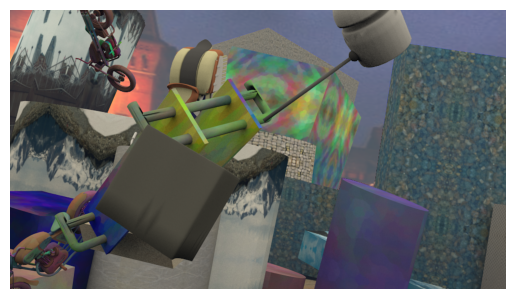

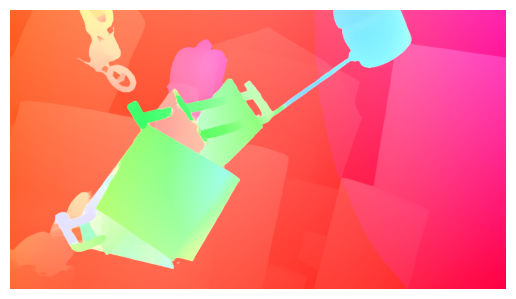

In [ ]:
import matplotlib.pyplot as plt

waft_flow_image = flow_viz.optical_flow_to_image(waft_flow[0].permute(1, 2, 0).cpu().numpy(), percentile=100)
flowseek_flow_image = flow_viz.optical_flow_to_image(flowseek_flow[0].permute(1, 2, 0).cpu().numpy(), percentile=100)

plt.imshow(image1[0].permute(1, 2, 0).cpu().numpy())
plt.axis('off')
plt.show()

plt.imshow(waft_flow_image)
plt.axis('off')
plt.show()

plt.imshow(flowseek_flow_image)
plt.axis('off')
plt.show()